<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    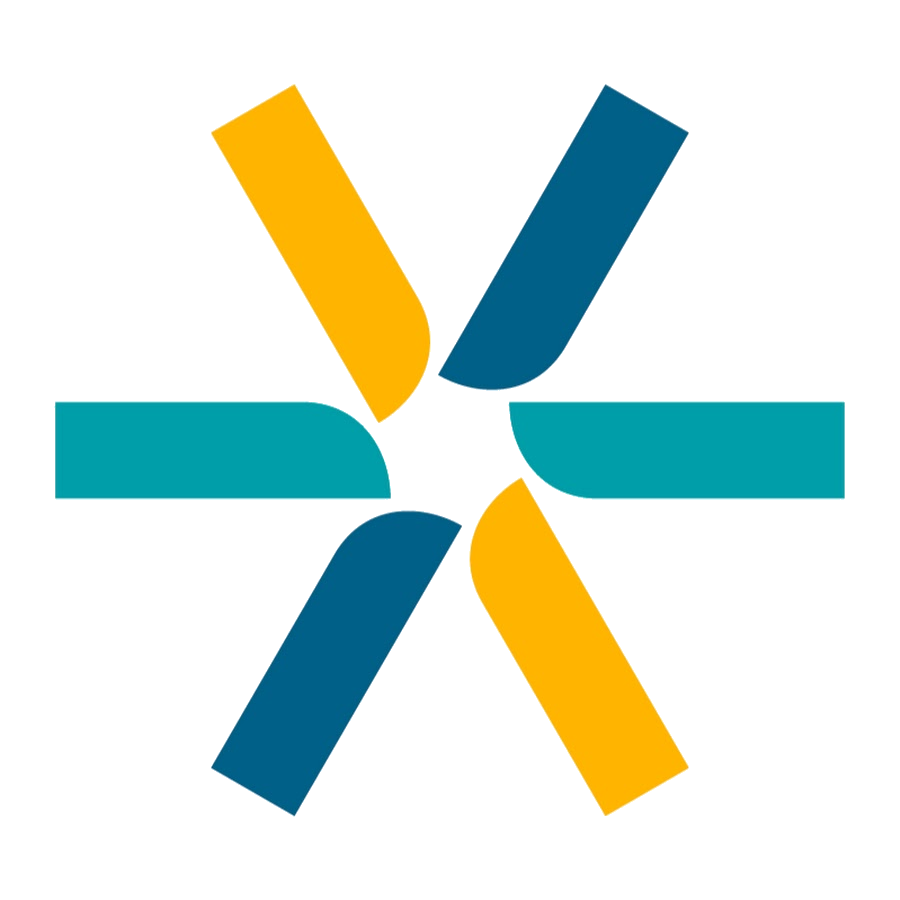
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">k vecinos más cercanos y Bayes ingenuo · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 6 · Modelos basados en instancias y probabilísticos</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 34 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La misma de la clase 32: ¿la demanda de este agente va a caer más de un 15 % el mes que viene, y con qué probabilidad? Ahora con dos algoritmos que no trazan una frontera lineal: uno hace votar a las filas más parecidas; el otro cuenta y multiplica probabilidades.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas filas, las mismas ocho predictoras relativas, el mismo corte temporal (entrenamiento hasta 2019-06) y la misma prueba. Así los resultados se comparan con la regresión logística de la clase 32 (AUC ~0,66).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Ver qué hace cada algoritmo por adentro: quiénes son los vecinos de una fila y cómo votan; qué cuenta Bayes ingenuo y cómo multiplica. Y sus perillas: k, la distancia y el escalado; la suposición de independencia y las tres variantes.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas secciones de la clase 34: 1 · los datos → A · k vecinos (sentencia, vecinos de una fila, k, escalado, distancias, dimensiones, regresión) → B · Bayes ingenuo (el ejemplo del material, la sentencia, las campanas, la posterior, la suposición violada, tres variantes) → C · comparativo → D · usarlo.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sobre la prueba, con las seis métricas de la clase 32. k se elige con validación cruzada <b>temporal</b> (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">TimeSeriesSplit</code>) sobre el entrenamiento.</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué hay que saber antes de modelar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Lo de la clase 32 sigue valiendo: desbalance (~17 % de caídas en entrenamiento, ~13 % en prueba), señales débiles en cada columna y corte por fecha. Hay dos cosas nuevas que importan para los algoritmos de hoy:</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Hay mucha más data que en el ejemplo.</b> 31 000 filas de entrenamiento contra 2 520 clientes: buscar vecinos cuesta más, y el k razonable es mucho más grande (√N ≈ 177).</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Dos pares de columnas están correlacionados.</b> <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_mes_ant</code> con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> (0,76: una es el valor absoluto de la otra) y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code> con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_residencial</code> (−0,76: las residenciales son todas de distribuidoras). Para los vecinos cuentan dos veces en la distancia; para Bayes ingenuo violan la independencia.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Y una diferencia de forma: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_hace_un_anio</code> falta en casi la mitad de las filas y ni los vecinos ni <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GaussianNB</code> aceptan faltantes, así que los dos llevan el mismo imputador que la logística.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos, listos</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Lo mismo que la clase 32, en una celda</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cargar, armar las ocho predictoras y el objetivo, partir por fecha, el flujo <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">preparado(modelo)</code> (imputar, escalar, modelo), <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">registrar()</code> con las seis métricas y ahora también el tiempo de predicción, la línea de base y la logística como referencia.</p></div>

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 130)
np.set_printoptions(suppress=True, precision=3)
warnings.filterwarnings("ignore", message="Skipping features without any observed values")   # primeros pliegues temporales sin var_hace_un_anio

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
base_lags = demanda[["serie", "periodo", "demanda_MWh"]]
for k in [1, 2, 12, 13]:
    t = base_lags.copy(); t["periodo"] = t["periodo"] + k
    demanda = demanda.merge(t.rename(columns={"demanda_MWh": f"lag{k}"}), on=["serie", "periodo"], how="left")

datos = demanda[demanda["lag1"] > 0].copy()
datos["ratio_dias"] = datos["periodo"].dt.days_in_month / (datos["periodo"] - 1).dt.days_in_month
datos["var_mes_ant"] = pd.Series(np.where(datos["lag2"] > 0, datos["lag1"] / datos["lag2"] - 1, np.nan), index=datos.index).clip(-1, 3)
datos["volatilidad"] = datos["var_mes_ant"].abs()
datos["var_hace_un_anio"] = pd.Series(np.where((datos["lag13"] > 0) & (datos["lag12"] >= 0), datos["lag12"] / datos["lag13"] - 1, np.nan), index=datos.index).clip(-1, 3)
datos["log_tamano"] = np.log10(datos["lag1"])
datos["mes_num"] = datos["periodo"].dt.month
datos["es_gran_usuario"] = (datos["categoria_demanda"] == "Gran Usuario").astype(int)
datos["es_residencial"] = (datos["categoria_tarifa"] == "Residencial").astype(int)
UMBRAL_CAIDA = 0.15
datos["cae_fuerte"] = (datos["demanda_MWh"] < (1 - UMBRAL_CAIDA) * datos["lag1"]).astype(int)
datos = datos.sort_values(["periodo", "serie"]).reset_index(drop=True)

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
OBJETIVO = "cae_fuerte"
CORTE = pd.Period("2019-06", freq="M")
ent_mask = datos["periodo"] <= CORTE
X_ent, X_pru = datos.loc[ent_mask, PREDICTORAS], datos.loc[~ent_mask, PREDICTORAS]
y_ent, y_pru = datos.loc[ent_mask, OBJETIVO], datos.loc[~ent_mask, OBJETIVO]
CV = TimeSeriesSplit(n_splits=5)

def preparado(modelo):
    """Imputar, escalar y recién entonces el modelo."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), modelo)

resultados = {}
def guardar(nombre, prob, t_fit, t_pred, modelo, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    resultados[nombre] = {"exactitud": accuracy_score(y_pru, pred), "precisión": precision_score(y_pru, pred, zero_division=0),
                          "exhaustividad": recall_score(y_pru, pred), "F1": f1_score(y_pru, pred), "AUC": roc_auc_score(y_pru, prob),
                          "log-loss": log_loss(y_pru, prob), "ajuste (ms)": t_fit, "predicción (ms)": t_pred, "modelo": modelo}

def registrar(nombre, modelo, umbral=0.5, cols=None):
    cols = PREDICTORAS if cols is None else cols
    t0 = time.perf_counter(); modelo.fit(X_ent[cols], y_ent); t_fit = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); prob = modelo.predict_proba(X_pru[cols])[:, 1]; t_pred = (time.perf_counter() - t0) * 1000
    guardar(nombre, prob, t_fit, t_pred, modelo, umbral)
    return modelo

registrar("línea de base (mayoritaria)", DummyClassifier(strategy="most_frequent"))
logistica = registrar("regresión logística (clase 32)", preparado(LogisticRegression()))
print(f"{len(X_ent)} filas de entrenamiento ({y_ent.mean() * 100:.1f} % caídas) · {len(X_pru)} de prueba ({y_pru.sum()} caídas)")
print(f"Referencias: línea de base AUC {resultados['línea de base (mayoritaria)']['AUC']:.3f} · logística AUC {resultados['regresión logística (clase 32)']['AUC']:.3f}, log-loss {resultados['regresión logística (clase 32)']['log-loss']:.3f}")

31415 filas de entrenamiento (17.1 % caídas) · 5982 de prueba (759 caídas)
Referencias: línea de base AUC 0.500 · logística AUC 0.663, log-loss 0.365


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">A · k vecinos más cercanos</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.1 · La sentencia: fit guarda, predict trabaja</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">KNeighborsClassifier(n_neighbors=5)</code>: votan cinco. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">fit</code> guarda las 31 000 filas; todo el cálculo está en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code>. Con 5 votos, p̂ solo puede valer 0, 0,2, 0,4, 0,6, 0,8 o 1.</p></div>

In [2]:
from sklearn.neighbors import KNeighborsClassifier

vecinos5 = preparado(KNeighborsClassifier(n_neighbors=5))
t0 = time.perf_counter(); vecinos5.fit(X_ent, y_ent); t_fit = (time.perf_counter() - t0) * 1000
t0 = time.perf_counter(); prob5 = vecinos5.predict_proba(X_pru)[:, 1]; t_pred = (time.perf_counter() - t0) * 1000
print(f"fit: {t_fit:.1f} ms (guardó {vecinos5[-1].n_samples_fit_} filas) · predict sobre {len(X_pru)}: {t_pred:.0f} ms · valores posibles de p̂: {sorted(set(prob5.round(1)))}")
tabla = X_pru.head().copy()
tabla["p̂ = votos/5"] = prob5[:5]
tabla["predict"] = vecinos5.predict(X_pru.head())
tabla["real"] = y_pru.head().values
tabla

fit: 142.5 ms (guardó 31415 filas) · predict sobre 5982: 194 ms · valores posibles de p̂: [np.float64(0.0), np.float64(0.2), np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0)]


,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,p̂ = votos/5,predict,real
31415,1.033333,0.029428,0.029428,0.053738,3.090951,7,1,0,0.0,0,0
31416,1.033333,0.054989,0.054989,0.017103,3.082777,7,1,0,0.2,0,0
31417,1.033333,-0.332686,0.332686,-0.266401,2.441544,7,1,0,0.4,0,0
31418,1.033333,-0.286159,0.286159,-0.180852,2.593948,7,1,0,0.0,0,0
31419,1.033333,-0.060227,0.060227,0.061857,4.299507,7,1,0,0.0,0,0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.2 · Los vecinos de una fila</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">kneighbors</code> da las distancias y las posiciones de los k vecinos en el entrenamiento. Se toma una fila de prueba que sí cayó y se muestran sus cinco vecinos, con sus datos y su clase. La predicción es su voto.</p></div>

In [3]:
prob_log = logistica.predict_proba(X_pru)[:, 1]
preproc = vecinos5[:-1]                                                 # imputar + escalar
knn5 = vecinos5[-1]
caidas = np.where(y_pru.to_numpy() == 1)[0]
i = int(caidas[np.argsort(prob_log[caidas])[len(caidas) // 2]])          # una caída real con probabilidad logística mediana
dist, pos = knn5.kneighbors(preproc.transform(X_pru.iloc[[i]]))
vecindario = X_ent.iloc[pos[0]].copy()
vecindario.insert(0, "serie", datos.loc[X_ent.index[pos[0]], "serie"].str.slice(0, 28).values)
vecindario.insert(1, "distancia", dist[0].round(2)); vecindario["clase"] = y_ent.iloc[pos[0]].values
fila = X_pru.iloc[[i]].copy(); fila.insert(0, "serie", datos.loc[X_pru.index[i], "serie"][:28]); fila.insert(1, "distancia", 0.0); fila["clase"] = f"? (real {y_pru.iloc[i]})"
print(f"Fila {X_pru.index[i]} ({datos.loc[X_pru.index[i], 'periodo']}) y sus 5 vecinos (distancia euclídea sobre las 8 columnas escaladas):")
display(pd.concat([fila, vecindario]).round(3))
print(f"Votos: {int(vecindario['clase'].sum())} de 5 por la caída → p̂ = {prob5[i]:.1f}; la logística le daba {prob_log[i]:.2f}")

Fila 37246 (2020-02) y sus 5 vecinos (distancia euclídea sobre las 8 columnas escaladas):


,serie,distancia,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,clase
37246,PIRENEOY | GUMAS/AUTOGENERAD,0.00,0.935,0.078,0.078,0.004,3.542,2,1,0,? (real 1)
14821,SAFAGCOY | GUMAS/AUTOGENERAD,0.63,0.903,0.071,0.071,-0.026,3.513,2,1,0,0
14403,EDELARFD | GUMES/GUPAS,0.64,0.903,0.067,0.067,0.034,3.611,2,1,0,0
27787,CELULI1Y | GUMAS/AUTOGENERAD,0.64,0.903,0.053,0.053,0.021,3.416,2,1,0,0
13864,BAGASA1Y | GUMAS/AUTOGENERAD,0.65,0.903,0.100,0.100,-0.011,3.375,2,1,0,0
28225,OWENROSY | GUMAS/AUTOGENERAD,0.65,0.903,0.050,0.050,-0.029,3.429,2,1,0,0


Votos: 0 de 5 por la caída → p̂ = 0.0; la logística le daba 0.16


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los vecinos son filas de otros agentes, de otros meses, que se parecen en las ocho columnas: el mismo tipo de tarifa, un tamaño parecido, una variación reciente parecida. La logística le da a esta fila una probabilidad mediana porque suma señales; los vecinos miran qué les pasó a los parecidos. Con solo cinco, el voto es muy ruidoso.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Chico, adecuado, grande: lo que k hace con la frontera</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Dos columnas, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">log_tamano</code> (escaladas), y tres k. Para que se vea algo con tanto desbalance, el color es la probabilidad de caída, no la clase.</p></div>

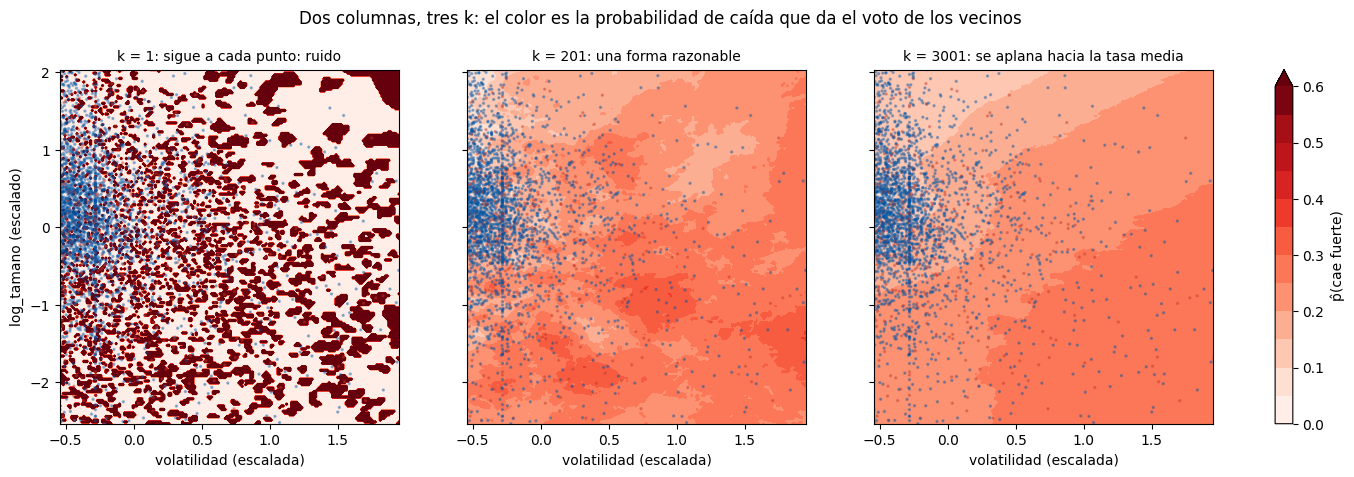

In [4]:
DOS = ["volatilidad", "log_tamano"]
prep2 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_ent[DOS]); Z2 = prep2.transform(X_ent[DOS])
lim1, lim2 = np.percentile(Z2[:, 0], [1, 97]), np.percentile(Z2[:, 1], [2, 99])
g1, g2 = np.meshgrid(np.linspace(*lim1, 200), np.linspace(*lim2, 200))
grilla = np.c_[g1.ravel(), g2.ravel()]
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, k, lectura in zip(ejes, [1, 201, 3001], ["sigue a cada punto: ruido", "una forma razonable", "se aplana hacia la tasa media"]):
    modelo_k = KNeighborsClassifier(n_neighbors=k).fit(Z2, y_ent)
    im = ax.contourf(g1, g2, modelo_k.predict_proba(grilla)[:, 1].reshape(g1.shape), levels=np.linspace(0, 0.6, 13), cmap="Reds", extend="max")
    muestra = np.random.default_rng(2026).choice(len(Z2), 3000, replace=False)
    ax.scatter(Z2[muestra, 0], Z2[muestra, 1], s=2, c=[ROJO if v else AZUL for v in y_ent.to_numpy()[muestra]], alpha=0.35)
    ax.set_xlim(*lim1); ax.set_ylim(*lim2); ax.set_title(f"k = {k}: {lectura}", fontsize=10); ax.set_xlabel("volatilidad (escalada)")
ejes[0].set_ylabel("log_tamano (escalado)")
fig.colorbar(im, ax=ejes, label="p̂(cae fuerte)", fraction=0.02)
fig.suptitle("Dos columnas, tres k: el color es la probabilidad de caída que da el voto de los vecinos", y=1.01)
plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con k = 1 el mapa es un mosaico: cada fila de entrenamiento pinta su alrededor. Con k = 201 aparece la forma: el riesgo sube con la volatilidad y en los agentes chicos (abajo a la derecha), y no de forma lineal. Con k = 3001 se aplana hacia la tasa media y solo queda la tendencia general. (Los puntos son una muestra del entrenamiento: azul no cayó, rojo cayó.) Una logística, con estas dos columnas, solo podría dibujar franjas paralelas.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.3 · Elegir k</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Validación cruzada temporal (5 pliegues de <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">TimeSeriesSplit</code>) sobre el entrenamiento, con el AUC. El material propone √N como punto de partida.</p></div>

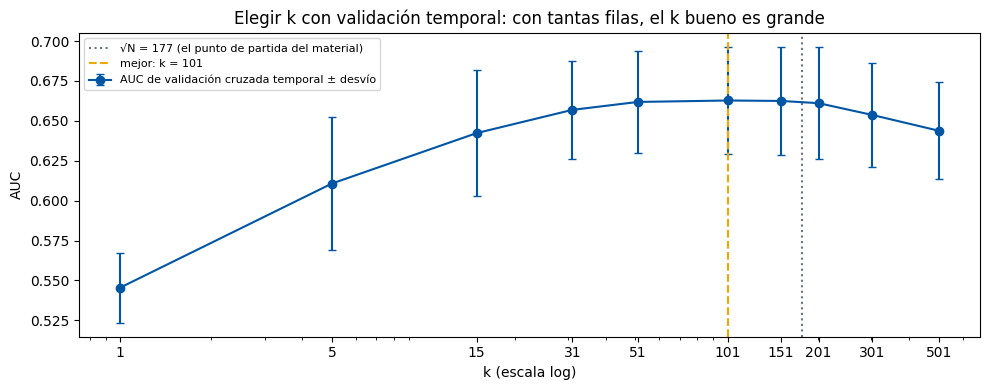

k vecinos, k=1                     AUC 0.594 · log-loss 7.164 · F1 0.288 · exhaustividad 0.316
k vecinos, k=5 (defecto)           AUC 0.679 · log-loss 1.764 · F1 0.259 · exhaustividad 0.203
k vecinos, k=101 (validación)      AUC 0.741 · log-loss 0.343 · F1 0.038 · exhaustividad 0.020
regresión logística (clase 32)     AUC 0.663 · log-loss 0.365 · F1 0.026 · exhaustividad 0.013


In [5]:
ks = [1, 5, 15, 31, 51, 101, 151, 201, 301, 501]
auc_cv = np.array([cross_val_score(preparado(KNeighborsClassifier(n_neighbors=k)), X_ent, y_ent, cv=CV, scoring="roc_auc") for k in ks])
mejor_k = ks[int(np.argmax(auc_cv.mean(axis=1)))]

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(ks, auc_cv.mean(axis=1), yerr=auc_cv.std(axis=1), marker="o", color=AZUL, capsize=3, label="AUC de validación cruzada temporal ± desvío")
ax.axvline(int(np.sqrt(len(X_ent))), color=GRIS, ls=":", lw=1.5, label=f"√N = {int(np.sqrt(len(X_ent)))} (el punto de partida del material)")
ax.axvline(mejor_k, color=AMBAR, ls="--", lw=1.5, label=f"mejor: k = {mejor_k}")
ax.set_xscale("log"); ax.set_xticks(ks); ax.set_xticklabels(ks); ax.set_xlabel("k (escala log)"); ax.set_ylabel("AUC"); ax.legend(fontsize=8)
ax.set_title("Elegir k con validación temporal: con tantas filas, el k bueno es grande")
plt.tight_layout(); plt.show()
registrar("k vecinos, k=1", preparado(KNeighborsClassifier(n_neighbors=1)))
registrar("k vecinos, k=5 (defecto)", vecinos5)
NOMBRE_KNN = f"k vecinos, k={mejor_k} (validación)"
mejor_knn = registrar(NOMBRE_KNN, preparado(KNeighborsClassifier(n_neighbors=mejor_k)))
for k in ["k vecinos, k=1", "k vecinos, k=5 (defecto)", NOMBRE_KNN, "regresión logística (clase 32)"]:
    r = resultados[k]; print(f"{k:34s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · F1 {r['F1']:.3f} · exhaustividad {r['exhaustividad']:.3f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con pocos vecinos el AUC es apenas mejor que la logística y el log-loss es pésimo (con k = 1 las probabilidades son 0 o 1, y cuando se equivoca paga muchísimo). Con k de cientos, los vecinos <b>le ganan claramente a la logística</b> en AUC y también en log-loss. Es la misma lectura que en la cátedra: la relación entre estas columnas y la caída no es lineal (la volatilidad y el tamaño interactúan, el efecto de los días depende del tipo de agente), y un algoritmo que mira a los parecidos la capta sin que nadie le diga la forma. La exhaustividad con 0,5 sigue siendo casi nula: el umbral es otro tema.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.4 · Sin escalar, decide el rango</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La distancia suma diferencias. Sin escalar, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">mes_num</code> (de 1 a 12) pesa mucho más que <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> (de 0,90 a 1,11) o que una variación de 0,05. Acá el efecto es más suave que en la cátedra, porque casi todas las columnas ya son relativas; pero se ve igual.</p></div>

In [6]:
sin_escalar = registrar(f"k vecinos, k={mejor_k}, sin escalar", make_pipeline(SimpleImputer(strategy="median"), KNeighborsClassifier(n_neighbors=mejor_k)))
rangos = (X_ent.max() - X_ent.min()).sort_values(ascending=False)
print("Rango de cada columna (lo que pesa en la distancia sin escalar):", rangos.round(2).to_dict())
solo_mes = make_pipeline(SimpleImputer(strategy="median"), KNeighborsClassifier(n_neighbors=mejor_k)).fit(X_ent[["mes_num"]], y_ent)
auc_solo = roc_auc_score(y_pru, solo_mes.predict_proba(X_pru[["mes_num"]])[:, 1])
print(f"AUC con k={mejor_k}: escalado {resultados[NOMBRE_KNN]['AUC']:.3f} · sin escalar {resultados[f'k vecinos, k={mejor_k}, sin escalar']['AUC']:.3f} · usando solo mes_num {auc_solo:.3f}")

Rango de cada columna (lo que pesa en la distancia sin escalar): {'mes_num': 11.0, 'log_tamano': 9.02, 'var_hace_un_anio': 4.0, 'var_mes_ant': 4.0, 'volatilidad': 3.0, 'es_gran_usuario': 1.0, 'es_residencial': 1.0, 'ratio_dias': 0.2}
AUC con k=101: escalado 0.741 · sin escalar 0.718 · usando solo mes_num 0.568


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.5 · Las tres distancias, y pesar por distancia</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Euclídea (el defecto), Manhattan, Chebyshev, y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">weights="distance"</code>.</p></div>

In [7]:
for nombre, modelo_d in [(f"k vecinos, k={mejor_k}, Manhattan", KNeighborsClassifier(n_neighbors=mejor_k, metric="manhattan")),
                         (f"k vecinos, k={mejor_k}, Chebyshev", KNeighborsClassifier(n_neighbors=mejor_k, metric="chebyshev")),
                         (f"k vecinos, k={mejor_k}, pesados por distancia", KNeighborsClassifier(n_neighbors=mejor_k, weights="distance"))]:
    registrar(nombre, preparado(modelo_d))
for k in [NOMBRE_KNN, f"k vecinos, k={mejor_k}, Manhattan", f"k vecinos, k={mejor_k}, Chebyshev", f"k vecinos, k={mejor_k}, pesados por distancia"]:
    r = resultados[k]; print(f"{k:42s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · predicción {r['predicción (ms)']:.0f} ms")

k vecinos, k=101 (validación)              AUC 0.741 · log-loss 0.343 · predicción 1114 ms
k vecinos, k=101, Manhattan                AUC 0.754 · log-loss 0.332 · predicción 1155 ms
k vecinos, k=101, Chebyshev                AUC 0.730 · log-loss 0.342 · predicción 1308 ms
k vecinos, k=101, pesados por distancia    AUC 0.744 · log-loss 0.342 · predicción 1034 ms


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.6 · Muchas dimensiones: todo queda lejos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los tres números de la diapositiva, simulados, y después columnas de ruido puro agregadas a las ocho reales.</p></div>

       2 dimensiones: distancia media entre dos puntos al azar en el hipercubo unitario = 0.52
       3 dimensiones: distancia media entre dos puntos al azar en el hipercubo unitario = 0.66
 1000000 dimensiones: distancia media entre dos puntos al azar en el hipercubo unitario = 408.32


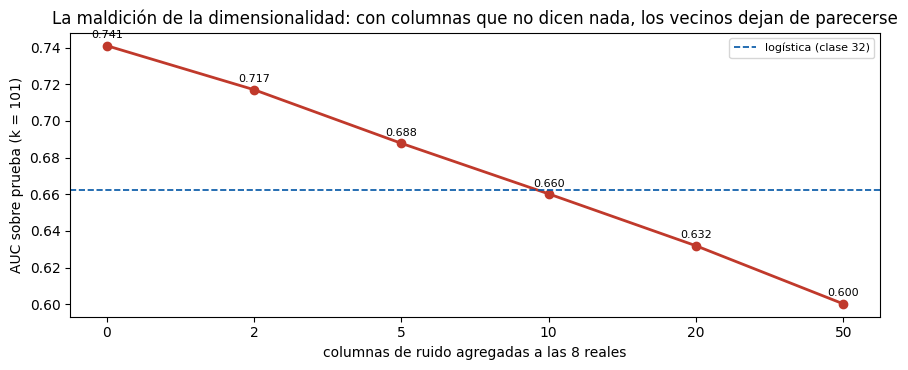

In [8]:
rng = np.random.default_rng(2026)
for dim, n in [(2, 100000), (3, 100000), (1000000, 10)]:
    a, b = rng.random((n, dim)), rng.random((n, dim))
    print(f"{dim:>8d} dimensiones: distancia media entre dos puntos al azar en el hipercubo unitario = {np.linalg.norm(a - b, axis=1).mean():.2f}")
del a, b

prep8 = preparado(KNeighborsClassifier())[:-1].fit(X_ent)
Z_ent, Z_pru = prep8.transform(X_ent), prep8.transform(X_pru)
extras = [0, 2, 5, 10, 20, 50]
auc_ruido = []
for extra in extras:
    ruido_ent, ruido_pru = rng.normal(size=(len(Z_ent), extra)), rng.normal(size=(len(Z_pru), extra))
    m = KNeighborsClassifier(n_neighbors=mejor_k).fit(np.c_[Z_ent, ruido_ent], y_ent)
    auc_ruido.append(roc_auc_score(y_pru, m.predict_proba(np.c_[Z_pru, ruido_pru])[:, 1]))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(len(extras)), auc_ruido, marker="o", color=ROJO, lw=2); ax.set_xticks(range(len(extras))); ax.set_xticklabels(extras)
ax.axhline(resultados["regresión logística (clase 32)"]["AUC"], color=AZUL, ls="--", lw=1.2, label="logística (clase 32)")
ax.set_xlabel("columnas de ruido agregadas a las 8 reales"); ax.set_ylabel(f"AUC sobre prueba (k = {mejor_k})"); ax.legend(fontsize=8)
for e, a_ in enumerate(auc_ruido): ax.text(e, a_ + 0.004, f"{a_:.3f}", ha="center", fontsize=8)
ax.set_title("La maldición de la dimensionalidad: con columnas que no dicen nada, los vecinos dejan de parecerse")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con 8 columnas reales, unas pocas de ruido ya empiezan a pesar, y con decenas la ventaja sobre la logística se esfuma: la distancia se llena de diferencias que no significan nada. La logística, en cambio, le pondría a esas columnas un coeficiente cercano a cero y seguiría igual. Es la razón para elegir con cuidado qué columnas entran a un k vecinos.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.7 · También para regresión: la demanda en MWh</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">KNeighborsRegressor</code>: los mismos vecinos, que en vez de votar promedian. Se prueba sobre el problema de las clases 29 y 31 (los MWh del mes, con los rezagos en niveles). Referencias de aquellas clases: la recta ~9 800 MWh; grado 2 + Lasso ~8 300.</p></div>

In [9]:
from sklearn.neighbors import KNeighborsRegressor

reg = demanda[demanda["lag1"].notna()].copy()                         # el conjunto de las clases 29 y 31
reg["mes_num"] = reg["periodo"].dt.month
reg["es_gran_usuario"] = (reg["categoria_demanda"] == "Gran Usuario").astype(int)
reg["es_residencial"] = (reg["categoria_tarifa"] == "Residencial").astype(int)
P29 = ["lag1", "lag2", "lag12", "mes_num", "es_gran_usuario", "es_residencial"]
r_ent = reg["periodo"] <= CORTE
def rmse(a, b): return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))
filas = []
for cols, etiqueta in [(P29, "seis columnas (clase 29)"), (["lag1"], "solo lag1")]:
    for k in [1, 5, 15]:
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=k)).fit(reg.loc[r_ent, cols], reg.loc[r_ent, "demanda_MWh"])
        filas.append({"columnas": etiqueta, "k": k, "RMSE sobre prueba (MWh)": rmse(reg.loc[~r_ent, "demanda_MWh"], m.predict(reg.loc[~r_ent, cols]))})
from sklearn.linear_model import LinearRegression
recta29 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()).fit(reg.loc[r_ent, P29], reg.loc[r_ent, "demanda_MWh"])
print(f"Referencia, la recta de la clase 29 recalculada: RMSE = {rmse(reg.loc[~r_ent, 'demanda_MWh'], recta29.predict(reg.loc[~r_ent, P29])):,.0f} MWh")
pd.DataFrame(filas).pivot(index="k", columns="columnas", values="RMSE sobre prueba (MWh)").round(0)

Referencia, la recta de la clase 29 recalculada: RMSE = 9,825 MWh


columnas,seis columnas (clase 29),solo lag1
k,,
1,14326.0,15934.0
5,13846.0,13112.0
15,17771.0,16501.0


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Al revés que en clasificación: para los MWh, los vecinos pierden contra la recta. La razón está en las colas largas de la clase 29. Un promedio de vecinos nunca puede dar un valor más alto que el de sus vecinos, y las distribuidoras gigantes tienen muy pocos parecidos: su predicción se arrastra hacia agentes más chicos. La recta, en cambio, extrapola: «este mes ≈ el mes pasado» funciona igual para 100 que para un millón de MWh. Los vecinos no extrapolan, y con estos datos eso pesa.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">B · Bayes ingenuo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.1 · El ejemplo del material, a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La tabla del clima de la diapositiva, igual que en la cátedra.</p></div>

In [10]:
from fractions import Fraction as F
condicionales = {"cielo soleado": (F(2, 9), F(3, 5)), "temperatura fría": (F(3, 9), F(1, 5)), "humedad alta": (F(3, 9), F(4, 5)), "viento": (F(3, 9), F(3, 5))}
a_priori = (F(9, 14), F(5, 14))
def posterior(condiciones):
    """Multiplica las condicionales de cada clase, por su a priori, y normaliza."""
    juega = a_priori[0]; no_juega = a_priori[1]
    for cond in condiciones: juega *= cond[0]; no_juega *= cond[1]
    return float(juega / (juega + no_juega)), float(no_juega / (juega + no_juega)), float(juega), float(no_juega)
p_si, p_no, num_si, num_no = posterior(condicionales.values())
print(f"Soleado, frío, húmedo y con viento: producto × a priori = {num_si:.4f} (jugó) contra {num_no:.4f} (no jugó) → normalizado: {p_si:.2f} y {p_no:.2f}. No se juega.")
sin_viento = dict(condicionales); sin_viento["viento"] = (F(6, 9), F(2, 5))        # P(sin viento | jugó), P(sin viento | no jugó)
p_si, p_no, _, _ = posterior(sin_viento.values())
print(f"La actividad, sin viento: {p_si:.2f} (jugó) contra {p_no:.2f} (no jugó). Sigue sin jugar, pero por poco.")

Soleado, frío, húmedo y con viento: producto × a priori = 0.0053 (jugó) contra 0.0206 (no jugó) → normalizado: 0.20 y 0.80. No se juega.
La actividad, sin viento: 0.44 (jugó) contra 0.56 (no jugó). Sigue sin jugar, pero por poco.


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.2 · La sentencia: GaussianNB, y lo que cuenta</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GaussianNB().fit(X, y)</code>: una media y un desvío por columna y por clase, más la a priori. Entrenar es contar. No hace falta escalar, pero sí imputar: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GaussianNB</code> no acepta faltantes.</p></div>

In [11]:
from sklearn.naive_bayes import GaussianNB

imputador = SimpleImputer(strategy="median").fit(X_ent)
bayes_flujo = make_pipeline(SimpleImputer(strategy="median"), GaussianNB())
t0 = time.perf_counter(); bayes_flujo.fit(X_ent, y_ent); t_fit = (time.perf_counter() - t0) * 1000
bayes = bayes_flujo[-1]
print(f"fit: {t_fit:.1f} ms · a priori P(y): {dict(zip(['no cae', 'cae fuerte'], bayes.class_prior_.round(3)))}")
aprendido = pd.DataFrame({("μ (media)", "no cae"): bayes.theta_[0], ("μ (media)", "cae"): bayes.theta_[1],
                          ("σ (desvío)", "no cae"): np.sqrt(bayes.var_[0]), ("σ (desvío)", "cae"): np.sqrt(bayes.var_[1])}, index=PREDICTORAS).round(3)
display(aprendido)
registrar("Bayes ingenuo gaussiano", make_pipeline(SimpleImputer(strategy="median"), GaussianNB()))
tabla = X_pru.head().copy()
tabla["p̂(cae)"] = bayes_flujo.predict_proba(X_pru.head())[:, 1].round(4)
tabla["predict"] = bayes_flujo.predict(X_pru.head()); tabla["real"] = y_pru.head().values
tabla

fit: 29.6 ms · a priori P(y): {'no cae': np.float64(0.829), 'cae fuerte': np.float64(0.171)}


μ (media)        σ (desvío)       
                    no cae    cae     no cae    cae
ratio_dias           1.002  0.993      0.051  0.054
var_mes_ant          0.037  0.122      0.377  0.595
volatilidad          0.183  0.308      0.333  0.524
var_hace_un_anio     0.027 -0.015      0.255  0.293
log_tamano           3.040  2.722      1.068  1.160
mes_num              6.236  6.051      3.337  3.322
es_gran_usuario      0.462  0.358      0.499  0.479
es_residencial       0.397  0.569      0.489  0.495

,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,p̂(cae),predict,real
31415,1.033333,0.029428,0.029428,0.053738,3.090951,7,1,0,0.0263,0,0
31416,1.033333,0.054989,0.054989,0.017103,3.082777,7,1,0,0.0268,0,0
31417,1.033333,-0.332686,0.332686,-0.266401,2.441544,7,1,0,0.0583,0,0
31418,1.033333,-0.286159,0.286159,-0.180852,2.593948,7,1,0,0.0448,0,0
31419,1.033333,-0.060227,0.060227,0.061857,4.299507,7,1,0,0.0217,0,0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Una campana por clase</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Para cuatro columnas: el histograma de cada clase y la campana que Bayes le ajustó. Donde se separan, la columna discrimina; donde la columna no tiene forma de campana, la suposición se nota.</p></div>

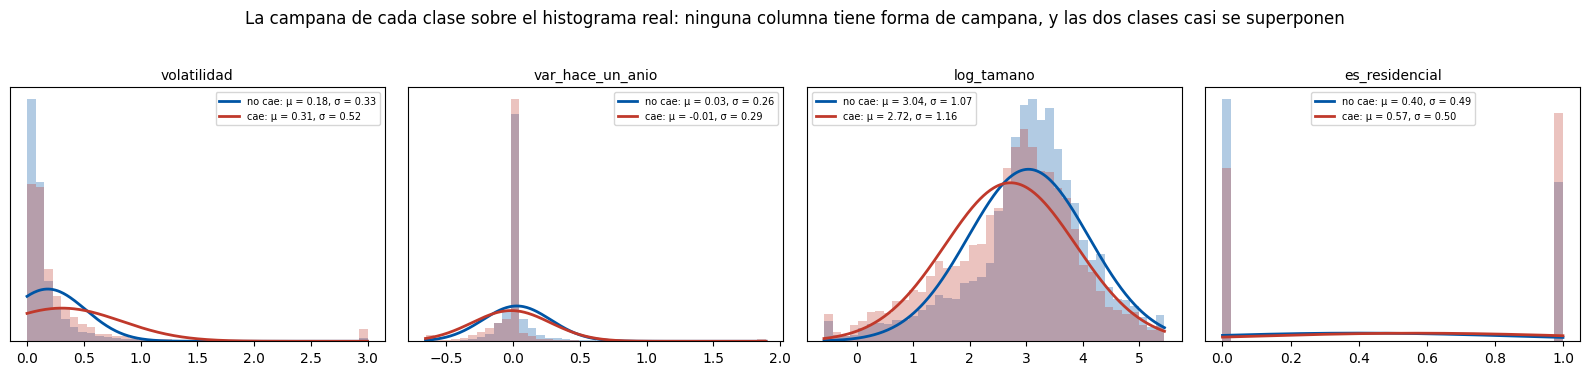

In [12]:
X_ent_imp = pd.DataFrame(imputador.transform(X_ent), columns=PREDICTORAS, index=X_ent.index)
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col in zip(ejes, ["volatilidad", "var_hace_un_anio", "log_tamano", "es_residencial"]):
    j = PREDICTORAS.index(col)
    lo, hi = X_ent_imp[col].quantile([0.005, 0.995])
    xs = np.linspace(lo, hi, 300)
    for clase, color, etiqueta in [(0, AZUL, "no cae"), (1, ROJO, "cae")]:
        ax.hist(X_ent_imp.loc[y_ent == clase, col].clip(lo, hi), bins=40, density=True, color=color, alpha=0.3)
        mu, sigma = bayes.theta_[clase, j], np.sqrt(bayes.var_[clase, j])
        ax.plot(xs, np.exp(-0.5 * ((xs - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi)), color=color, lw=2, label=f"{etiqueta}: μ = {mu:.2f}, σ = {sigma:.2f}")
    ax.set_title(col, fontsize=10); ax.set_yticks([]); ax.legend(fontsize=7)
fig.suptitle("La campana de cada clase sobre el histograma real: ninguna columna tiene forma de campana, y las dos clases casi se superponen", y=1.03)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Acá la suposición gaussiana sufre más que en el ejemplo de la cátedra. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> es positiva con una cola larguísima, y la campana le pone probabilidad a valores negativos. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_hace_un_anio</code> tiene un pico enorme en la mediana: es la mitad de las filas, que no tenían dato y se imputaron. Y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_residencial</code> es 0/1, no una campana. Las dos clases están corridas, pero muy poco.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.3 · Cómo se arma la posterior de una fila</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El estimador paso a paso para la misma fila de A.2: la densidad de cada columna en cada clase, el producto con la a priori (en logaritmos) y la normalización. La diferencia entre clases, columna por columna, es lo que cada una aporta a favor de la caída.</p></div>

Fila 37246: log P(y) = [-0.19 -1.76] · Σ log P(x | y) = [-3.54 -5.17] · log posterior = [-3.73 -6.93]
p̂(cae) a mano = 0.0392 · predict_proba = 0.0392   (k vecinos con k = 5 le daba 0.0; la logística 0.16)


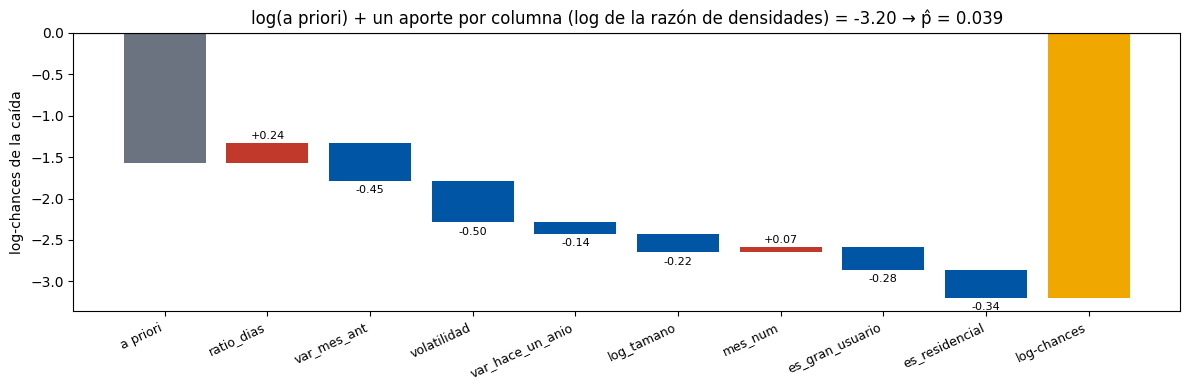

In [13]:
from scipy.stats import norm

def log_verosimilitudes(fila):
    """log P(xⱼ | y) para cada columna j y cada clase, con la campana aprendida (sobre la fila ya imputada)."""
    return np.array([[norm.logpdf(fila[j], bayes.theta_[clase, j], np.sqrt(bayes.var_[clase, j])) for j in range(len(PREDICTORAS))] for clase in [0, 1]])
fila_imp = imputador.transform(X_pru.iloc[[i]])[0]
lv = log_verosimilitudes(fila_imp)
log_post = np.log(bayes.class_prior_) + lv.sum(axis=1)
p_cae = np.exp(log_post[1]) / np.exp(log_post).sum()
print(f"Fila {X_pru.index[i]}: log P(y) = {np.log(bayes.class_prior_).round(2)} · Σ log P(x | y) = {lv.sum(axis=1).round(2)} · log posterior = {log_post.round(2)}")
print(f"p̂(cae) a mano = {p_cae:.4f} · predict_proba = {bayes_flujo.predict_proba(X_pru.iloc[[i]])[0, 1]:.4f}   (k vecinos con k = 5 le daba {prob5[i]:.1f}; la logística {prob_log[i]:.2f})")
aportes_b = pd.Series(lv[1] - lv[0], index=PREDICTORAS)
sesgo_b = np.log(bayes.class_prior_[1] / bayes.class_prior_[0])

fig, ax = plt.subplots(figsize=(12, 4))
etiquetas = ["a priori"] + PREDICTORAS + ["log-chances"]; acum = sesgo_b
ax.bar(0, sesgo_b, color=GRIS)
for k, v in enumerate(aportes_b, start=1):
    ax.bar(k, v, bottom=acum, color=ROJO if v >= 0 else AZUL); ax.text(k, acum + v + (0.05 if v >= 0 else -0.15), f"{v:+.2f}", ha="center", fontsize=8); acum += v
ax.bar(len(etiquetas) - 1, acum, color=AMBAR); ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(etiquetas))); ax.set_xticklabels(etiquetas, rotation=25, ha="right", fontsize=9); ax.set_ylabel("log-chances de la caída")
ax.set_title(f"log(a priori) + un aporte por columna (log de la razón de densidades) = {acum:.2f} → p̂ = {1 / (1 + np.exp(-acum)):.3f}")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.4 · La suposición ingenua, violada</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Dos pares de columnas dicen casi lo mismo: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_mes_ant</code> / <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code> / <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_residencial</code>. Bayes los multiplica como si fueran independientes: cuenta dos veces la misma evidencia. Se compara con la logística y se prueba sacar una columna de cada par.</p></div>

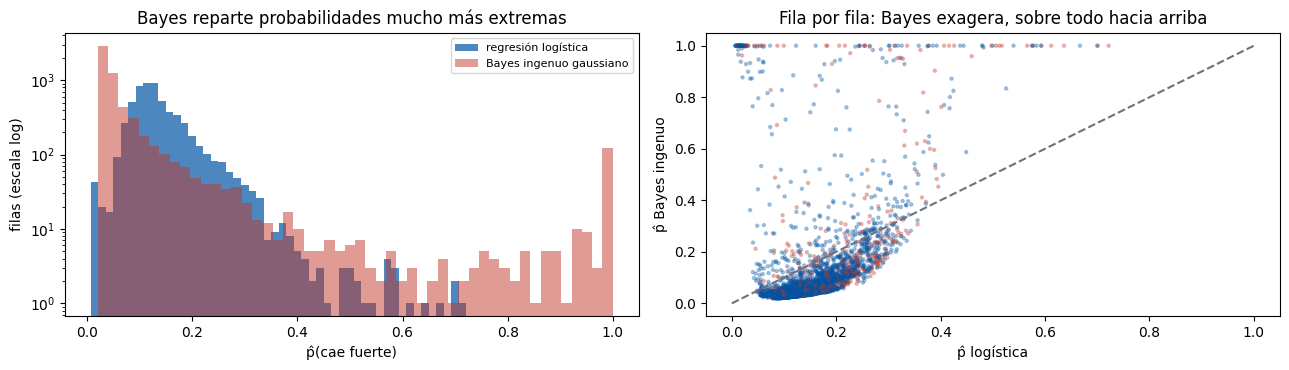

Filas con p̂ > 0,5: Bayes 3.6 % · logística 0.3 %   (caídas reales: 12.7 %)
Correlaciones: var_mes_ant–volatilidad 0.76 · es_gran_usuario–es_residencial -0.77
Bayes ingenuo gaussiano                              AUC 0.655 · log-loss 0.609
Bayes gaussiano, sin volatilidad                     AUC 0.651 · log-loss 0.514
Bayes gaussiano, sin es_gran_usuario                 AUC 0.689 · log-loss 0.599
Bayes gaussiano, sin volatilidad ni es_gran_usuario  AUC 0.687 · log-loss 0.506


In [14]:
prob_bayes = bayes_flujo.predict_proba(X_pru)[:, 1]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.8))
a.hist(prob_log, bins=50, color=AZUL, alpha=0.7, label="regresión logística"); a.hist(prob_bayes, bins=50, color=ROJO, alpha=0.5, label="Bayes ingenuo gaussiano")
a.set_yscale("log"); a.set_xlabel("p̂(cae fuerte)"); a.set_ylabel("filas (escala log)"); a.legend(fontsize=8); a.set_title("Bayes reparte probabilidades mucho más extremas")
b.scatter(prob_log, prob_bayes, s=5, alpha=0.3, c=[ROJO if v == 1 else AZUL for v in y_pru]); b.plot([0, 1], [0, 1], color=GRIS, ls="--")
b.set_xlabel("p̂ logística"); b.set_ylabel("p̂ Bayes ingenuo"); b.set_title("Fila por fila: Bayes exagera, sobre todo hacia arriba")
plt.tight_layout(); plt.show()
print(f"Filas con p̂ > 0,5: Bayes {np.mean(prob_bayes > 0.5) * 100:.1f} % · logística {np.mean(prob_log > 0.5) * 100:.1f} %   (caídas reales: {y_pru.mean() * 100:.1f} %)")
print(f"Correlaciones: var_mes_ant–volatilidad {X_ent['var_mes_ant'].corr(X_ent['volatilidad']):.2f} · es_gran_usuario–es_residencial {X_ent['es_gran_usuario'].corr(X_ent['es_residencial']):.2f}")
for quitar in [["volatilidad"], ["es_gran_usuario"], ["volatilidad", "es_gran_usuario"]]:
    cols = [c for c in PREDICTORAS if c not in quitar]
    registrar(f"Bayes gaussiano, sin {' ni '.join(quitar)}", make_pipeline(SimpleImputer(strategy="median"), GaussianNB()), cols=cols)
for k in ["Bayes ingenuo gaussiano", "Bayes gaussiano, sin volatilidad", "Bayes gaussiano, sin es_gran_usuario", "Bayes gaussiano, sin volatilidad ni es_gran_usuario"]:
    r = resultados[k]; print(f"{k:52s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Bayes le da probabilidad mayor a 0,5 a unas diez veces más filas que la logística, y del lado bajo también se va a valores mucho más chicos: exagera en las dos direcciones. Parte es la doble cuenta de las columnas correlacionadas, y parte es que las campanas no ajustan (una cola larga le da a la volatilidad alta una razón de densidades enorme). Los dos pares no hacen el mismo daño. Sacar <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> mejora el log-loss (las probabilidades se vuelven más razonables) pero no el AUC. Sacar <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code> mejora el AUC (de ~0,66 a ~0,69): esa doble cuenta sí desordenaba las filas, porque dos columnas 0/1 casi opuestas, tratadas como campanas independientes, empujaban dos veces en la misma dirección.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.5 · Tres suposiciones: gaussiana, multinomial, Bernoulli</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada variante con las columnas que mejor le cuadran: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GaussianNB</code> a las seis continuas, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">BernoulliNB</code> a las dos binarias, y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">MultinomialNB</code> a las columnas no negativas (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">mes_num</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code>). Nuestros datos no tienen conteos como los de un texto, así que la multinomial va a fallar por la misma razón que en la cátedra: supone una composición (cuánto de cada cosa en un total) y acá cada columna es una magnitud por sí misma. Después, el problema del cero y el α de Laplace.</p></div>

In [15]:
from sklearn.naive_bayes import MultinomialNB, BernoulliNB

CONTINUAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num"]
NO_NEGATIVAS = ["mes_num", "volatilidad", "ratio_dias"]
BINARIAS = ["es_gran_usuario", "es_residencial"]
for nombre, modelo_nb, cols in [("Bayes gaussiano, 6 continuas", make_pipeline(SimpleImputer(strategy="median"), GaussianNB()), CONTINUAS),
                                ("Bayes multinomial, 3 no negativas", make_pipeline(SimpleImputer(strategy="median"), MultinomialNB(alpha=1.0)), NO_NEGATIVAS),
                                ("Bayes Bernoulli, 2 binarias", BernoulliNB(), BINARIAS)]:
    registrar(nombre, modelo_nb, cols=cols)
    r = resultados[nombre]; print(f"{nombre:34s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · F1 {r['F1']:.3f}")
for alpha in [1.0, 0.0]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        bern = BernoulliNB(alpha=alpha, force_alpha=True).fit(X_ent[BINARIAS], y_ent)
    print(f"Bernoulli con alpha={alpha}: P(gran usuario | no cae) = {np.exp(bern.feature_log_prob_[0, 0]):.4f}, P(gran usuario | cae) = {np.exp(bern.feature_log_prob_[1, 0]):.4f} · "
          f"P(residencial | no cae) = {np.exp(bern.feature_log_prob_[0, 1]):.4f}, P(residencial | cae) = {np.exp(bern.feature_log_prob_[1, 1]):.4f}")
print("Con 31 000 filas, α = 1 casi no mueve las frecuencias; con un valor que no aparece nunca para una clase, es lo que evita el cero.")

Bayes gaussiano, 6 continuas       AUC 0.709 · log-loss 0.592 · F1 0.151
Bayes multinomial, 3 no negativas  AUC 0.592 · log-loss 0.378 · F1 0.005
Bayes Bernoulli, 2 binarias        AUC 0.491 · log-loss 0.391 · F1 0.000
Bernoulli con alpha=1.0: P(gran usuario | no cae) = 0.4618, P(gran usuario | cae) = 0.3577 · P(residencial | no cae) = 0.3975, P(residencial | cae) = 0.5693
Bernoulli con alpha=0.0: P(gran usuario | no cae) = 0.4618, P(gran usuario | cae) = 0.3576 · P(residencial | no cae) = 0.3975, P(residencial | cae) = 0.5693
Con 31 000 filas, α = 1 casi no mueve las frecuencias; con un valor que no aparece nunca para una clase, es lo que evita el cero.


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La gaussiana con <b>solo las seis continuas</b> mejora mucho (AUC ~0,71, mejor que la logística): las dos columnas 0/1, metidas como campanas y además correlacionadas, eran lo peor del modelo de ocho. Darle a cada variante las columnas que le corresponden importa. La multinomial no sirve, como se anticipó. Y Bernoulli con las dos binarias queda <b>por debajo de 0,5</b>: con dos columnas solo hay tres combinaciones posibles (residencial, gran usuario, distribuidor no residencial), y el orden de riesgo entre ellas cambió entre el entrenamiento y la prueba. En la cátedra quejas y estado casi decidían solas; acá el tipo de agente, solo, no alcanza ni para ordenar.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">C · El comparativo: cuál resultó mejor, y cómo se elige</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La matriz, el AUC y la decisión</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Todo lo registrado, con las seis métricas y los dos tiempos. El tiempo de predicción es nuevo: para los vecinos crece con los datos.</p></div>

In [16]:
METRICAS = ["exactitud", "precisión", "exhaustividad", "F1", "AUC", "log-loss", "ajuste (ms)", "predicción (ms)"]
matriz = pd.DataFrame({k: {m: v[m] for m in METRICAS} for k, v in resultados.items()}).T.astype(float)
(matriz.style.format({m: "{:.3f}" for m in METRICAS[:6]}).format({"ajuste (ms)": "{:.1f}", "predicción (ms)": "{:.1f}"})
       .background_gradient(subset=["exactitud", "precisión", "exhaustividad", "F1", "AUC"], cmap="RdYlGn")
       .background_gradient(subset=["log-loss", "ajuste (ms)", "predicción (ms)"], cmap="RdYlGn_r"))

,exactitud,precisión,exhaustividad,F1,AUC,log-loss,ajuste (ms),predicción (ms)
línea de base (mayoritaria),0.873119,0.000000,0.000000,0.000000,0.500000,4.573242,4.0,1.1
regresión logística (clase 32),0.873454,0.555556,0.013175,0.025740,0.662507,0.364760,64.4,2.9
"k vecinos, k=1",0.801237,0.263736,0.316206,0.287597,0.593963,7.164143,112.6,107.7
"k vecinos, k=5 (defecto)",0.852725,0.358140,0.202899,0.259041,0.679440,1.763572,92.2,298.8
"k vecinos, k=101 (validación)",0.873955,0.600000,0.019763,0.038265,0.741016,0.343047,93.0,1114.1
"k vecinos, k=101, sin escalar",0.872618,0.400000,0.007905,0.015504,0.717845,0.344832,102.7,430.4
"k vecinos, k=101, Manhattan",0.873287,0.545455,0.007905,0.015584,0.754047,0.332256,96.2,1154.7
"k vecinos, k=101, Chebyshev",0.872952,0.470588,0.010540,0.020619,0.729732,0.341522,86.9,1307.8
"k vecinos, k=101, pesados por distancia",0.873621,0.531915,0.032938,0.062035,0.743808,0.342249,97.0,1033.9
Bayes ingenuo gaussiano,0.860749,0.327103,0.092227,0.143885,0.654627,0.608933,33.7,4.9


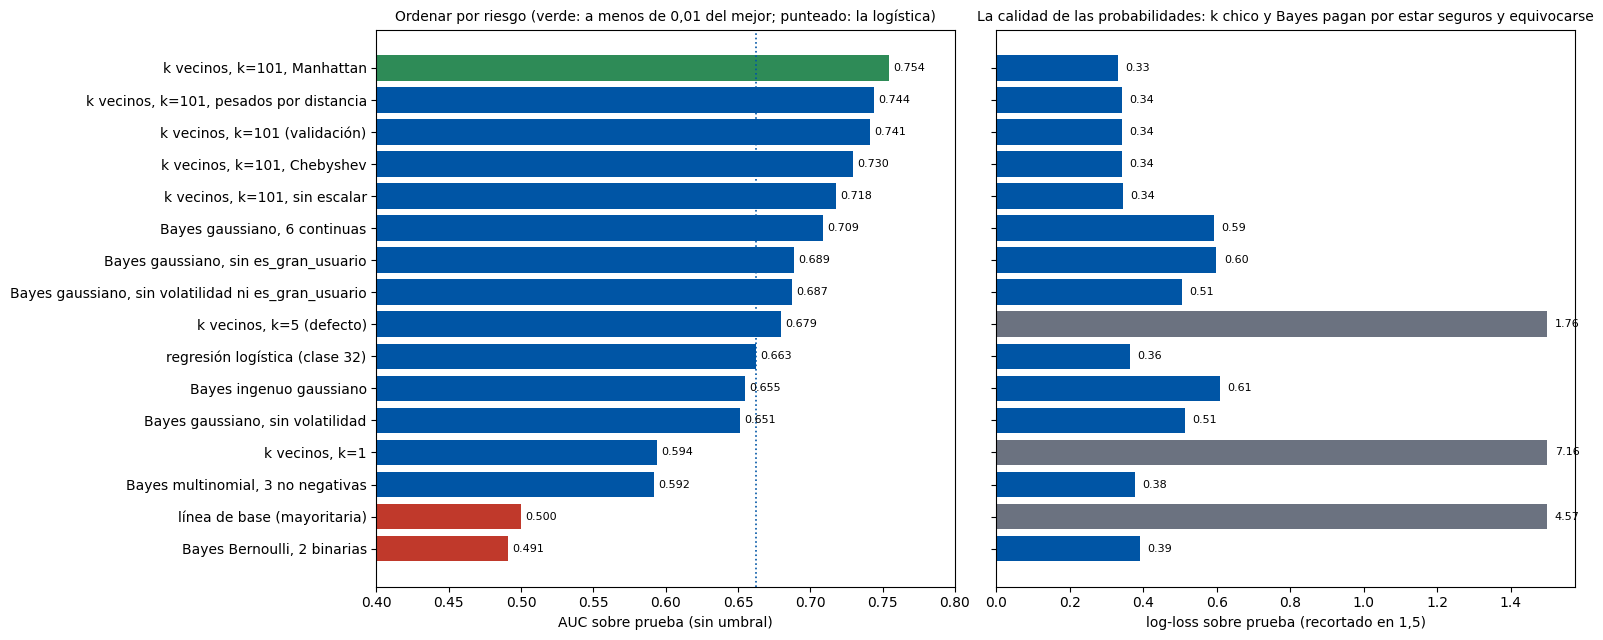

In [17]:
fig, (a, b) = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
orden = matriz.sort_values("AUC", ascending=False)
mejor_auc = orden["AUC"].max()
a.barh(orden.index, orden["AUC"], color=[VERDE if v >= mejor_auc - 0.01 else (ROJO if v < 0.55 else AZUL) for v in orden["AUC"]]); a.invert_yaxis(); a.set_xlim(0.4, 0.8)
for k, v in enumerate(orden["AUC"]): a.text(v + 0.003, k, f"{v:.3f}", va="center", fontsize=8)
a.axvline(resultados["regresión logística (clase 32)"]["AUC"], color=AZUL, ls=":", lw=1.2)
a.set_xlabel("AUC sobre prueba (sin umbral)"); a.set_title("Ordenar por riesgo (verde: a menos de 0,01 del mejor; punteado: la logística)", fontsize=10)
b.barh(orden.index, orden["log-loss"].clip(upper=1.5), color=[AZUL if v < 1 else GRIS for v in orden["log-loss"]])
for k, v in enumerate(orden["log-loss"]): b.text(min(v, 1.5) + 0.02, k, f"{v:.2f}", va="center", fontsize=8)
b.set_xlabel("log-loss sobre prueba (recortado en 1,5)"); b.set_title("La calidad de las probabilidades: k chico y Bayes pagan por estar seguros y equivocarse", fontsize=10)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La elección</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los vecinos ganan</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Con el k elegido por validación temporal, escalado y distancia euclídea, los vecinos ordenan mejor que la logística (AUC ~0,74 contra ~0,66) y además dan mejores probabilidades (menor log-loss). Es la variante final. Manhattan sale algo mejor sobre prueba (~0,75), pero para elegirla habría que compararla en la validación, no acá; los pesos por distancia empatan; Chebyshev, k chico y sin escalar pierden.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">El precio</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Predecir cuesta buscar entre 31 000 filas, y crece con los datos; el archivo del modelo guarda todo el entrenamiento. Y para la regresión en MWh los vecinos no sirven: no extrapolan a los agentes gigantes.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Bayes ingenuo</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Con las ocho columnas queda cerca de la logística en AUC y peor en log-loss: sus probabilidades exageran, porque las campanas no ajustan y dos pares de columnas cuentan doble. Con solo las seis continuas sube a ~0,71. Sirve por lo que es: casi gratis y explicable columna por columna.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">El umbral</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Igual que en la clase 32: con 0,5 ninguno anticipa casi nada. Se decide aparte, según el costo de cada error.</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">D · Usarlo: cada fila, explicada por los dos</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Dos agentes nuevos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los dos agentes inventados de la clase 32. Los vecinos dicen cuántos de sus parecidos cayeron; Bayes y la logística dan su probabilidad.</p></div>

In [18]:
nuevo = pd.DataFrame([
    {"ratio_dias": 31 / 28, "var_mes_ant": 0.02, "volatilidad": 0.02, "var_hace_un_anio": 0.08, "log_tamano": np.log10(80000), "mes_num": 3, "es_gran_usuario": 0, "es_residencial": 1},
    {"ratio_dias": 28 / 31, "var_mes_ant": 0.60, "volatilidad": 0.60, "var_hace_un_anio": np.nan, "log_tamano": np.log10(150), "mes_num": 2, "es_gran_usuario": 1, "es_residencial": 0},
], index=["distribuidora grande · marzo", "gran usuario chico · febrero"])
knn_final, prep_final = mejor_knn[-1], mejor_knn[:-1]
dist_n, pos_n = knn_final.kneighbors(prep_final.transform(nuevo[PREDICTORAS]))
nuevo[f"vecinos que cayeron (de {mejor_k})"] = [int(y_ent.iloc[p].sum()) for p in pos_n]
nuevo["p̂ vecinos"] = mejor_knn.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ Bayes"] = bayes_flujo.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ logística"] = logistica.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo

,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,vecinos que cayeron (de 101),p̂ vecinos,p̂ Bayes,p̂ logística
distribuidora grande · marzo,1.107143,0.02,0.02,0.08,4.903090,3,0,1,15,0.149,0.066,0.110
gran usuario chico · febrero,0.903226,0.60,0.60,NaN,2.176091,2,1,0,28,0.277,0.237,0.243


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Diez filas, con los vecinos que votaron</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Diez filas de prueba que cubren el rango de p̂ de los vecinos: cuántos de sus vecinos cayeron, la distancia al más cercano y al más lejano, lo que dice Bayes y lo real. Una fila con vecinos lejanos está en una zona rala: su voto es menos confiable.</p></div>

In [19]:
prob_knn = mejor_knn.predict_proba(X_pru)[:, 1]
objetivos = np.linspace(prob_knn.min(), prob_knn.max(), 10)
elegidos, usados = [], set()
for objetivo in objetivos:
    for candidato in np.argsort(np.abs(prob_knn - objetivo), kind="stable"):
        if candidato not in usados: elegidos.append(candidato); usados.add(candidato); break
elegidos = np.array(elegidos)
dist10, pos10 = knn_final.kneighbors(prep_final.transform(X_pru.iloc[elegidos]))
explicado = X_pru.iloc[elegidos].copy()
explicado.insert(0, "serie", datos.loc[X_pru.index[elegidos], "serie"].str.slice(0, 30).values)
explicado["vecinos que cayeron"] = [int(y_ent.iloc[p].sum()) for p in pos10]
explicado["p̂ vecinos"] = prob_knn[elegidos].round(3)
explicado["distancia al 1.º"] = dist10[:, 0].round(2); explicado[f"distancia al {mejor_k}.º"] = dist10[:, -1].round(2)
explicado["p̂ Bayes"] = prob_bayes[elegidos].round(3)
explicado["real"] = y_pru.iloc[elegidos].values
explicado.index.name = "fila"
(explicado.style.format(precision=2)
    .background_gradient(subset=["p̂ vecinos", "p̂ Bayes"], cmap="RdYlGn_r", vmin=0, vmax=0.6)
    .set_caption(f"Diez filas de prueba que cubren el rango de p̂ de los vecinos (k = {mejor_k}): cuántos cayeron, distancias, Bayes y lo real"))

,serie,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,vecinos que cayeron,p̂ vecinos,distancia al 1.º,distancia al 101.º,p̂ Bayes,real
fila,,,,,,,,,,,,,,,
31450,APELPALD | TARIFA USUARIO NO R,1.03,-0.02,0.02,0.07,4.51,7,0,0,0,0.00,0.15,0.63,0.03,0
31452,APLAMAOY | GUMAS/AUTOGENERADOR,1.03,-0.16,0.16,0.09,3.15,7,1,0,6,0.06,0.11,0.45,0.03,0
31502,C16OCTUW | TARIFA USUARIO NO R,1.03,0.17,0.17,1.77,2.35,7,0,0,13,0.13,1.25,3.82,0.88,0
31741,DAKAZA1Z | GUMAS/AUTOGENERADOR,1.03,0.70,0.70,0.11,3.69,7,1,0,19,0.19,0.41,1.60,0.16,0
31517,CAPSADUZ | GUMAS/AUTOGENERADOR,1.03,-0.64,0.64,0.56,1.89,7,1,0,25,0.25,1.26,2.36,0.20,0
31469,AVEXLLCY | GUMAS/AUTOGENERADOR,1.03,2.71,2.71,0.09,2.81,7,1,0,32,0.32,1.03,2.37,1.00,0
32468,CSBERN3W | RESIDENCIAL,1.00,0.35,0.35,-0.15,3.24,8,0,1,38,0.38,0.19,0.92,0.14,0
33195,CRAWSOUW | RESIDENCIAL,0.97,-0.14,0.14,0.13,3.65,9,0,1,44,0.44,0.22,0.67,0.09,0
33018,CALFAVQW | TARIFA BASE ELECTRO,0.97,0.07,0.07,-0.13,1.53,9,0,1,51,0.51,0.42,0.72,0.17,0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los mismos diez, explicados por Bayes ingenuo</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La explicación de Bayes es aditiva, como la de la logística: log de la a priori más un aporte por columna, el log de la razón de densidades.</p></div>

In [20]:
aportes_bayes = pd.DataFrame([log_verosimilitudes(imputador.transform(X_pru.iloc[[j]])[0])[1] - log_verosimilitudes(imputador.transform(X_pru.iloc[[j]])[0])[0] for j in elegidos],
                             columns=PREDICTORAS, index=X_pru.index[elegidos])
tabla_b = aportes_bayes.copy()
tabla_b.insert(0, "log a priori", sesgo_b)
tabla_b["log-chances"] = tabla_b.sum(axis=1)
tabla_b["p̂ Bayes"] = 1 / (1 + np.exp(-tabla_b["log-chances"]))
tabla_b.index.name = "fila"
lim_b = np.abs(aportes_bayes.to_numpy()).max()
(tabla_b.style.format("{:+.2f}").format("{:.2f}", subset=["log a priori", "log-chances"]).format("{:.3f}", subset=["p̂ Bayes"])
    .background_gradient(subset=PREDICTORAS, cmap="RdBu_r", vmin=-lim_b, vmax=lim_b)
    .set_caption("Cómo se arma cada posterior: log a priori + un aporte por columna (rojo favorece la caída) = log-chances; después, σ = p̂"))

,log a priori,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,log-chances,p̂ Bayes
fila,,,,,,,,,,,
31450,-1.58,-0.15,-0.47,-0.49,-0.17,-0.32,-0.01,+0.19,-0.34,-3.34,0.034
31452,-1.58,-0.15,-0.43,-0.49,-0.17,-0.15,-0.01,-0.28,-0.34,-3.60,0.027
31502,-1.58,-0.15,-0.39,-0.49,+4.67,+0.08,-0.01,+0.19,-0.34,1.97,0.877
31741,-1.58,-0.15,+0.62,+0.48,-0.18,-0.25,-0.01,-0.28,-0.34,-1.68,0.157
31517,-1.58,-0.15,+0.34,+0.29,+0.12,+0.24,-0.01,-0.28,-0.34,-1.38,0.201
31469,-1.58,-0.15,+15.17,+17.86,-0.17,-0.06,-0.01,-0.28,-0.34,30.43,1.000
32468,-1.58,-0.06,-0.19,-0.34,-0.00,-0.16,-0.03,+0.19,+0.37,-1.80,0.142
33195,-1.58,+0.08,-0.44,-0.50,-0.18,-0.24,-0.05,+0.19,+0.37,-2.35,0.087
33018,-1.58,+0.08,-0.46,-0.50,-0.03,+0.39,-0.05,+0.19,+0.37,-1.59,0.170


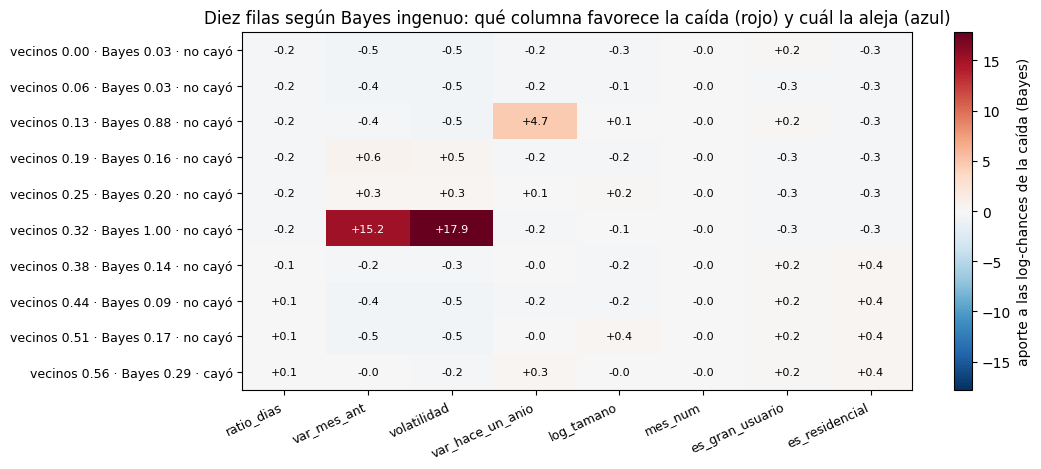

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(aportes_bayes.to_numpy(), cmap="RdBu_r", vmin=-lim_b, vmax=lim_b, aspect="auto")
ax.set_xticks(range(len(PREDICTORAS))); ax.set_xticklabels(PREDICTORAS, rotation=25, ha="right", fontsize=9)
ax.set_yticks(range(len(elegidos))); ax.set_yticklabels([f"vecinos {pv:.2f} · Bayes {pb:.2f} · {'cayó' if r == 1 else 'no cayó'}" for pv, pb, r in zip(explicado["p̂ vecinos"], explicado["p̂ Bayes"], explicado["real"])], fontsize=9)
for r_ in range(aportes_bayes.shape[0]):
    for cidx in range(aportes_bayes.shape[1]):
        v = aportes_bayes.iloc[r_, cidx]; ax.text(cidx, r_, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > lim_b / 2 else "black")
plt.colorbar(im, ax=ax, label="aporte a las log-chances de la caída (Bayes)")
ax.set_title("Diez filas según Bayes ingenuo: qué columna favorece la caída (rojo) y cuál la aleja (azul)")
plt.tight_layout(); plt.show()

In [22]:
def fmt(col, v):
    if pd.isna(v): return "faltante, imputado"
    if col == "log_tamano": return f"{10 ** v:,.0f} MWh el mes anterior".replace(",", ".")
    if col in ("var_mes_ant", "var_hace_un_anio"): return f"{v * 100:+.0f} %"
    if col == "volatilidad": return f"{v * 100:.0f} %"
    if col == "ratio_dias": return f"{v:.3f}"
    return f"{v:.0f}"
for fila_id, j in zip(aportes_bayes.index, elegidos):
    ap = aportes_bayes.loc[fila_id]
    partes = []
    for col in ap.abs().sort_values(ascending=False).index[:2]:
        jj = PREDICTORAS.index(col)
        partes.append(f"{ap[col]:+.1f} por {col} ({fmt(col, X_pru.loc[fila_id, col])}: {'más' if ap[col] > 0 else 'menos'} probable entre las que caen, μ {bayes.theta_[1, jj]:.2f} σ {np.sqrt(bayes.var_[1, jj]):.2f}, que entre las que no, μ {bayes.theta_[0, jj]:.2f} σ {np.sqrt(bayes.var_[0, jj]):.2f})")
    real = "cayó" if y_pru.iloc[j] == 1 else "no cayó"
    print(f"{datos.loc[fila_id, 'serie'][:30]} ({real}): vecinos p̂ {prob_knn[j]:.2f} ({int(y_ent.iloc[pos10[list(elegidos).index(j)]].sum())} de {mejor_k} cayeron); "
          f"Bayes p̂ {prob_bayes[j]:.3f}: parte de {sesgo_b:.2f} (la a priori, {bayes.class_prior_[1] * 100:.0f} % de caídas); " + "; ".join(partes) + ".")

APELPALD | TARIFA USUARIO NO R (no cayó): vecinos p̂ 0.00 (0 de 101 cayeron); Bayes p̂ 0.034: parte de -1.58 (la a priori, 17 % de caídas); -0.5 por volatilidad (2 %: menos probable entre las que caen, μ 0.31 σ 0.52, que entre las que no, μ 0.18 σ 0.33); -0.5 por var_mes_ant (-2 %: menos probable entre las que caen, μ 0.12 σ 0.60, que entre las que no, μ 0.04 σ 0.38).
APLAMAOY | GUMAS/AUTOGENERADOR (no cayó): vecinos p̂ 0.06 (6 de 101 cayeron); Bayes p̂ 0.027: parte de -1.58 (la a priori, 17 % de caídas); -0.5 por volatilidad (16 %: menos probable entre las que caen, μ 0.31 σ 0.52, que entre las que no, μ 0.18 σ 0.33); -0.4 por var_mes_ant (-16 %: menos probable entre las que caen, μ 0.12 σ 0.60, que entre las que no, μ 0.04 σ 0.38).
C16OCTUW | TARIFA USUARIO NO R (no cayó): vecinos p̂ 0.13 (13 de 101 cayeron); Bayes p̂ 0.877: parte de -1.58 (la a priori, 17 % de caídas); +4.7 por var_hace_un_anio (+177 %: más probable entre las que caen, μ -0.01 σ 0.29, que entre las que no, μ 0.03 σ 

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La misma predicción, en una aplicación</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se guardan los dos modelos de esta clase con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">joblib</code>. La app los carga junto con la logística de la clase 32 (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">modelo_cammesa_32.joblib</code>, si está en la carpeta) y muestra las tres probabilidades lado a lado, con el umbral como control. El archivo de los vecinos pesa lo que pesan los datos: guardar el modelo es guardar el entrenamiento.</p></div>

In [23]:
import joblib

joblib.dump(mejor_knn, "modelo_cammesa_34_knn.joblib")
joblib.dump(bayes_flujo, "modelo_cammesa_34_bayes.joblib")
for archivo, modelo_mem in [("modelo_cammesa_34_knn.joblib", mejor_knn), ("modelo_cammesa_34_bayes.joblib", bayes_flujo)]:
    cargado = joblib.load(archivo)
    print(f"{archivo:32s} mismas probabilidades tras guardar y cargar: {np.allclose(cargado.predict_proba(X_pru), modelo_mem.predict_proba(X_pru))}"
          f" · {Path(archivo).stat().st_size / 1024:,.0f} KB")

modelo_cammesa_34_knn.joblib     mismas probabilidades tras guardar y cargar: True · 4,740 KB
modelo_cammesa_34_bayes.joblib   mismas probabilidades tras guardar y cargar: True · 2 KB


In [24]:
%%writefile app_cammesa_34.py
# Clase 34 sobre CAMMESA · k vecinos y Bayes ingenuo, contra la logística · aplicación Streamlit
# Para abrirla, desde la carpeta del cuaderno:  streamlit run app_cammesa_34.py
import calendar
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
AZUL, ROJO = "#0055a5", "#c0392b"
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

st.set_page_config(page_title="¿Va a caer fuerte la demanda?", layout="centered")
st.title("¿La demanda de este agente va a caer fuerte?")
st.caption("Regresión logística (clase 32), k vecinos y Bayes ingenuo gaussiano (clase 34), sobre demanda-ltimos-aos.csv (CAMMESA).")

# ---------- 1 · Los modelos guardados por los cuadernos ----------
MODELOS = {
    "regresión logística": ("modelo_cammesa_32.joblib", "Clase_32_regresion_logistica_y_softmax_CAMMESA.ipynb"),
    "k vecinos": ("modelo_cammesa_34_knn.joblib", "Clase_34_k_vecinos_y_Bayes_ingenuo_CAMMESA.ipynb"),
    "Bayes ingenuo": ("modelo_cammesa_34_bayes.joblib", "Clase_34_k_vecinos_y_Bayes_ingenuo_CAMMESA.ipynb"),
}
PROPIOS = ["k vecinos", "Bayes ingenuo"]

@st.cache_resource
def cargar(archivo):
    return joblib.load(archivo)

modelos = {}
for nombre, (archivo, cuaderno) in MODELOS.items():
    if Path(archivo).exists():
        modelos[nombre] = cargar(archivo)
    elif nombre in PROPIOS:
        st.error(f"Falta {archivo}. Ejecutar antes el cuaderno {cuaderno}, que lo genera."); st.stop()
    else:
        st.warning(f"Falta {archivo} (lo genera {cuaderno}): la comparación se muestra sin {nombre}.")
config = json.loads(Path("umbral_cammesa_32.json").read_text(encoding="utf-8")) if Path("umbral_cammesa_32.json").exists() else {"umbral": 0.15}

# ---------- 2 · La historia del agente ----------
st.subheader("Historia del agente")
c1, c2 = st.columns(2)
lag1 = c1.number_input("Demanda del mes anterior (MWh)", 1.0, 1_600_000.0, 5_000.0, step=100.0)
lag2 = c1.number_input("Demanda de hace dos meses (MWh)", 0.0, 1_600_000.0, 4_800.0, step=100.0)
conoce_anio = c1.checkbox("Conozco el año pasado", value=True)
lag12 = c1.number_input("Hace un año: el mismo mes (MWh)", 0.0, 1_600_000.0, 5_200.0, step=100.0, disabled=not conoce_anio)
lag13 = c1.number_input("Hace un año: el mes anterior (MWh)", 0.0, 1_600_000.0, 5_000.0, step=100.0, disabled=not conoce_anio)
anio = c2.number_input("Año", 2017, 2030, 2020)
mes = MESES.index(c2.selectbox("Mes a predecir", MESES, index=1)) + 1
tipo = c2.radio("Tipo de agente", ["Distribuidor · residencial", "Distribuidor · no residencial", "Gran usuario"])
umbral = c2.slider("Umbral de decisión", 0.05, 0.60, float(config["umbral"]), step=0.01)

anio_ant, mes_ant = (anio - 1, 12) if mes == 1 else (anio, mes - 1)
var_mes_ant = float(np.clip(lag1 / lag2 - 1, -1, 3)) if lag2 > 0 else np.nan
var_anio = float(np.clip(lag12 / lag13 - 1, -1, 3)) if conoce_anio and lag13 > 0 else np.nan
fila = pd.DataFrame([{"ratio_dias": calendar.monthrange(anio, mes)[1] / calendar.monthrange(anio_ant, mes_ant)[1],
                      "var_mes_ant": var_mes_ant, "volatilidad": abs(var_mes_ant) if not np.isnan(var_mes_ant) else np.nan,
                      "var_hace_un_anio": var_anio, "log_tamano": np.log10(lag1), "mes_num": mes,
                      "es_gran_usuario": int(tipo == "Gran usuario"), "es_residencial": int(tipo == "Distribuidor · residencial")}])[PREDICTORAS]

# ---------- 3 · Probabilidad y decisión de cada modelo ----------
probs = {nombre: float(m.predict_proba(fila)[0, 1]) for nombre, m in modelos.items()}
st.subheader("Predicción")
for col, (nombre, p) in zip(st.columns(len(probs)), probs.items()):
    col.metric(nombre, f"{p * 100:.1f} %".replace(".", ","))
    col.markdown(f":{'red' if p >= umbral else 'blue'}[**{'alarma' if p >= umbral else 'sin alarma'}**] con umbral {umbral:.2f}".replace(".", ","))
fig, ax = plt.subplots(figsize=(8, 0.6 + 0.55 * len(probs)))
ax.barh(list(probs), list(probs.values()), color=[ROJO if p >= umbral else AZUL for p in probs.values()])
ax.axvline(umbral, color="black", ls="--", lw=1.5, label=f"umbral = {umbral:.2f}")
for k, p in enumerate(probs.values()): ax.text(min(p + 0.01, 0.9), k, f"{p:.3f}", va="center")
ax.set_xlim(0, 1); ax.set_xlabel("p̂(cae fuerte)"); ax.invert_yaxis(); ax.legend(loc="lower right")
plt.tight_layout(); st.pyplot(fig)

# ---------- 4 · Por qué ----------
st.subheader("Por qué")
pestanas = dict(zip(modelos, st.tabs(list(modelos))))
if "k vecinos" in modelos:
    with pestanas["k vecinos"]:
        m = modelos["k vecinos"]; knn = m[-1]
        dist, pos = knn.kneighbors(m[:-1].transform(fila))
        votos = knn._y[pos[0]]
        st.write(f"De sus **{knn.n_neighbors}** vecinos más parecidos en el entrenamiento, **{int(votos.sum())}** cayeron fuerte: p̂ = {votos.mean():.3f}. "
                 f"Distancia al más cercano {dist[0, 0]:.2f}, al más lejano {dist[0, -1]:.2f} (sobre las columnas escaladas).")
if "Bayes ingenuo" in modelos:
    with pestanas["Bayes ingenuo"]:
        m = modelos["Bayes ingenuo"]; nb = m[-1]; x = m[:-1].transform(fila)[0]
        def logpdf(v, mu, var): return -0.5 * np.log(2 * np.pi * var) - (v - mu) ** 2 / (2 * var)
        aportes = logpdf(x, nb.theta_[1], nb.var_[1]) - logpdf(x, nb.theta_[0], nb.var_[0])
        base = np.log(nb.class_prior_[1] / nb.class_prior_[0])
        st.write(f"Parte de **{base:.2f}** log-chances (la a priori) y suma, por columna, el log de la razón de densidades. Total = **{base + aportes.sum():.2f}**.")
        fig, ax = plt.subplots(figsize=(8, 3.6))
        ax.barh(PREDICTORAS, aportes, color=[ROJO if v > 0 else AZUL for v in aportes]); ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
        ax.set_xlabel("aporte a las log-chances (rojo: hacia la caída)"); plt.tight_layout(); st.pyplot(fig)
if "regresión logística" in modelos:
    with pestanas["regresión logística"]:
        m = modelos["regresión logística"]; z = m[:-1].transform(fila)[0]; lg = m[-1]
        aportes = lg.coef_[0] * z
        st.write(f"Parte de **{lg.intercept_[0]:.2f}** log-chances y suma coeficiente × valor escalado. Puntaje = **{lg.intercept_[0] + aportes.sum():.2f}**.")
        fig, ax = plt.subplots(figsize=(8, 3.6))
        ax.barh(PREDICTORAS, aportes, color=[ROJO if v > 0 else AZUL for v in aportes]); ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
        ax.set_xlabel("aporte a las log-chances (rojo: hacia la caída)"); plt.tight_layout(); st.pyplot(fig)

with st.expander("Ver la fila que reciben los modelos"):
    st.dataframe(fila)

Writing app_cammesa_34.py


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Cómo abrirla</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit</code> en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">aa2026</code>: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit run app_cammesa_34.py</code> desde la carpeta del cuaderno. Para ver también la logística, corré antes el cuaderno de la clase 32 en la misma carpeta (genera <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">modelo_cammesa_32.joblib</code>); si no está, la app avisa y sigue con los dos de esta clase.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Desde el cuaderno:</b> la celda siguiente la lanza sin consola; entrar a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">http://localhost:8501</code> y, para cortarla, interrumpir el kernel (■).</p></div>

In [25]:
import sys
print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
!"{sys.executable}" -m streamlit run app_cammesa_34.py --server.headless true

Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).
^C


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">E · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Los vecinos no entrenan:</b> <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">fit</code> guarda y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code> busca. Con 31 000 filas el k bueno es de cientos (elegido con validación temporal), el escalado no es opcional y las columnas de ruido los arruinan.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>En la clasificación de caídas, los vecinos ganan:</b> AUC ~0,74 contra ~0,66 de la logística, y mejores probabilidades. La relación entre volatilidad, tamaño, días y tipo de agente no es lineal, y mirar a los parecidos la capta sin decir la forma.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>En la regresión de MWh, pierden:</b> un promedio de vecinos no extrapola, y los agentes gigantes tienen pocos parecidos. La recta de la clase 29 sigue siendo mejor ahí.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Bayes ingenuo cuenta y multiplica.</b> Con columnas que no son campanas y dos pares correlacionados, exagera las probabilidades; sacar una columna de cada par mejora el log-loss, no el orden. Es casi gratis y se explica columna por columna en log-chances, como la logística.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Y usarlo:</b> los dos modelos se guardan con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">joblib</code> y la app los compara con la logística sobre la misma fila. El archivo de los vecinos pesa lo que pesan los datos.</p></div>